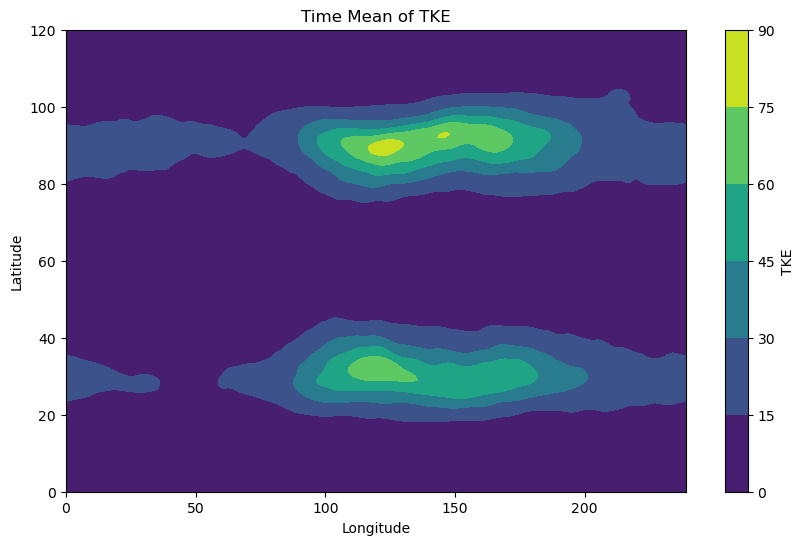

In [5]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# Load the NetCDF file
ds = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/TKE_monthly_2.5x2.5_2-11.nc')

# Calculate the time mean of the bidimensional field
time_mean = ds['tke'].mean(dim='time').loc[250,:,:]

# Plotting
plt.figure(figsize=(10, 6))
plt.contourf(time_mean,cmap='viridis')
plt.title('Time Mean of TKE')
plt.colorbar(label='TKE')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()


In [4]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

dic_ASYM = np.load('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/dictionaries/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51_DIC.npy',allow_pickle=True)
dic_SYM = np.load('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_KS/tot/dictionaries/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51_DIC.npy',allow_pickle=True)


In [7]:
persistences_ASYM = []
for i in range(len(dic_ASYM))[1:]:
    persistences_ASYM.append(dic_ASYM[i]['persistence'])

persistences_SYM = []
for i in range(len(dic_SYM))[1:]:
    persistences_SYM.append(dic_SYM[i]['persistence'])

mean_persistence_ASYM = sum(persistences_ASYM) / len(persistences_ASYM)
mean_persistence_SYM = sum(persistences_SYM) / len(persistences_SYM)



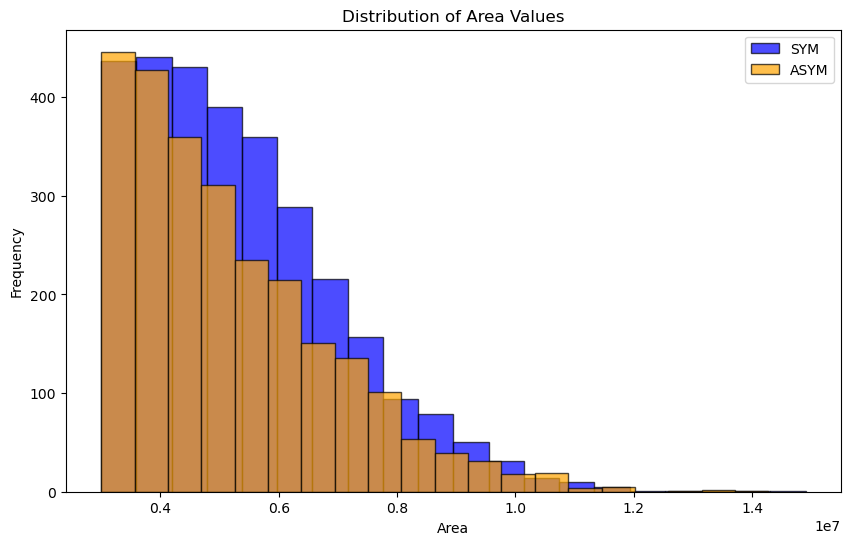

/tmp/ipykernel_133787/893350134.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([areas_SYM, areas_ASYM], labels=['SYM', 'ASYM'], patch_artist=True,


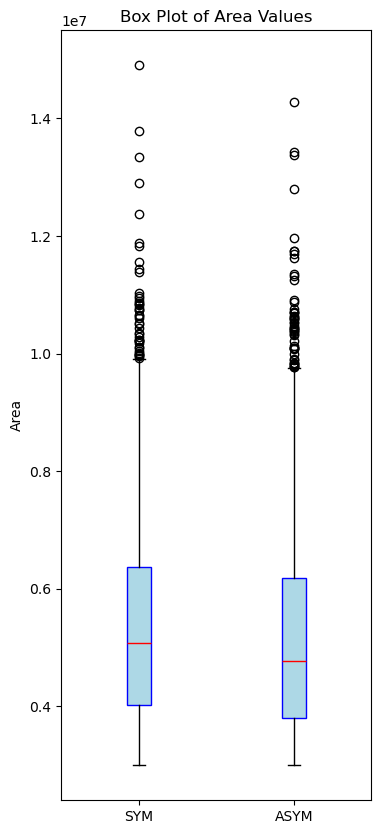

Mean Area SYM: 5367292.400519095
Mean Area ASYM: 5176385.704123982


In [17]:
areas_ASYM = []
for i in range(len(dic_ASYM))[1:]:
    areas_ASYM.append(sum(dic_ASYM[i]['area'])/dic_ASYM[i]['persistence'])

areas_SYM = []
for i in range(len(dic_SYM))[1:]:
    areas_SYM.append(sum(dic_SYM[i]['area'])/dic_SYM[i]['persistence'])

mean_area_ASYM = sum(areas_ASYM) / len(areas_ASYM)
mean_area_SYM = sum(areas_SYM) / len(areas_SYM)

plt.figure(figsize=(10, 6))
plt.hist(areas_SYM, bins=20, alpha=0.7, label='SYM', color='blue', edgecolor='black')
plt.hist(areas_ASYM, bins=20, alpha=0.7, label='ASYM', color='orange', edgecolor='black')
plt.title('Distribution of Area Values')
plt.xlabel('Area')
plt.ylabel('Frequency')
plt.legend()
plt.show()

plt.figure(figsize=(4,10))
plt.boxplot([areas_SYM, areas_ASYM], labels=['SYM', 'ASYM'], patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='blue'),
            medianprops=dict(color='red'),
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'))
plt.title('Box Plot of Area Values')
plt.ylabel('Area')
plt.show()
print("Mean Area SYM:", mean_area_SYM)
print("Mean Area ASYM:", mean_area_ASYM)


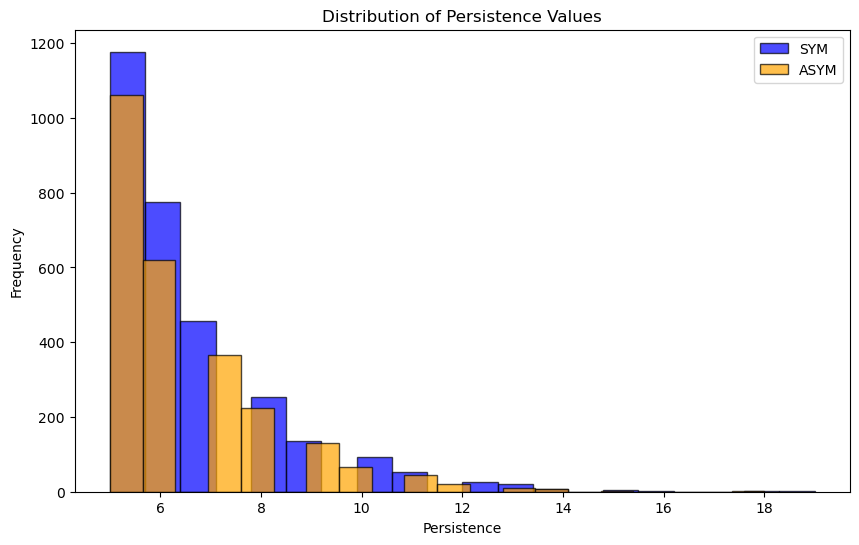

In [11]:
plt.figure(figsize=(10, 6))
plt.hist(persistences_SYM, bins=20, alpha=0.7, label='SYM', color='blue', edgecolor='black')
plt.hist(persistences_ASYM, bins=20, alpha=0.7, label='ASYM', color='orange', edgecolor='black')
plt.title('Distribution of Persistence Values')
plt.xlabel('Persistence')
plt.ylabel('Frequency')
plt.legend()
plt.show()


/tmp/ipykernel_133787/2066129464.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([persistences_SYM, persistences_ASYM], labels=['SYM', 'ASYM'], patch_artist=True,


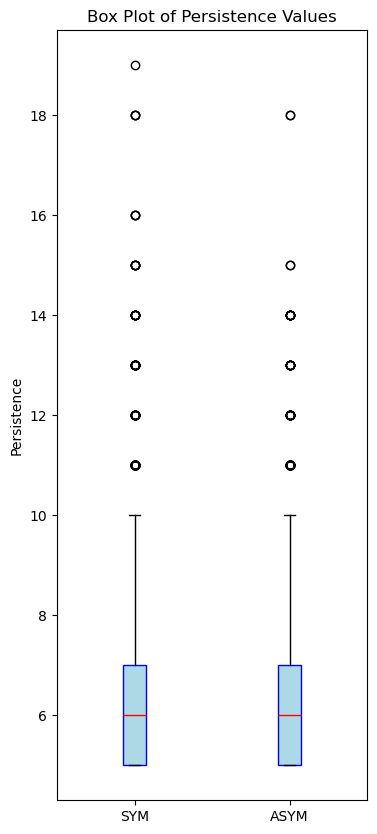

In [15]:
plt.figure(figsize=(4,10))
plt.boxplot([persistences_SYM, persistences_ASYM], labels=['SYM', 'ASYM'], patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='blue'),
            medianprops=dict(color='red'),
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'))
plt.title('Box Plot of Persistence Values')
plt.ylabel('Persistence')
plt.show()

In [16]:
print("Mean Persistence SYM:", mean_persistence_SYM)
print("Mean Persistence ASYM:", mean_persistence_ASYM)

Mean Persistence SYM: 6.437686939182453
Mean Persistence ASYM: 6.36320939334638


In [1]:
import xarray as xr
import numpy as np
from tqdm import tqdm 

base_path = '/home/links/mf671/DATA/isca_data'

experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_baseline_st_KS',
]

ds_length = 18000  # Number of time steps to consider

persistences_list = []
intensities_list = []

box_edges=[[40,70,-180,180],
           [40,70,75,160]]

for i,experiment in enumerate(experiments):
    ds = xr.open_dataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc').isel(time=slice(0, ds_length))
    dic = np.load(f'{base_path}/{experiment}/tot/dictionaries/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51_DIC.npy', allow_pickle=True)
    LWAA = ds['LWAA_tracked']
    persistences = []
    intensities = []
    inspected_labels = []
    print(np.unique(LWAA[45,:,:].loc[box_edges[i][0]:box_edges[i][1],box_edges[i][2]:box_edges[i][3]]))
    print(LWAA.shape)

    for t in tqdm(range(len(ds['time']))):
        for l in np.unique(LWAA[t,:,:].loc[box_edges[i][0]:box_edges[i][1],box_edges[i][2]:box_edges[i][3]])[1:]:
            if l not in inspected_labels:
                inspected_labels.append(l)
                persistences.append(dic[l]['persistence'])
                intensities.append(np.sum(dic[l]['intensity'])/dic[l]['persistence'])
    
    persistences_list.append(persistences)
    intensities_list.append(intensities)


[0]
(18000, 61, 240)


100%|███████████████████████████████████████████████████████████████| 18000/18000 [00:14<00:00, 1201.67it/s]


[0]
(18000, 61, 240)


100%|███████████████████████████████████████████████████████████████| 18000/18000 [00:14<00:00, 1220.31it/s]


/tmp/ipykernel_177355/2454797316.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(persistences_list, labels=['SYM', 'ASYM'], patch_artist=True,


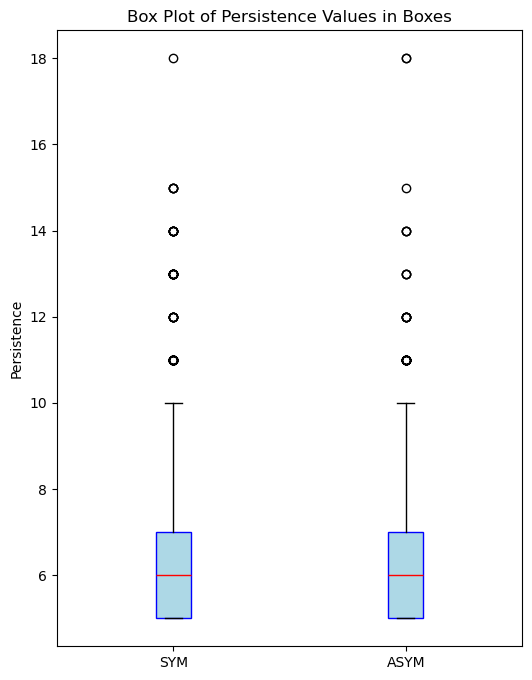

In [3]:
import matplotlib.pyplot as plt


plt.figure(figsize=(6, 8))
plt.boxplot(persistences_list, labels=['SYM', 'ASYM'], patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='blue'),
            medianprops=dict(color='red'),
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'))
plt.title('Box Plot of Persistence Values in Boxes')
plt.ylabel('Persistence')
plt.show()

/tmp/ipykernel_177355/3317300510.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(intensities_list, labels=['SYM', 'ASYM'], patch_artist=True,


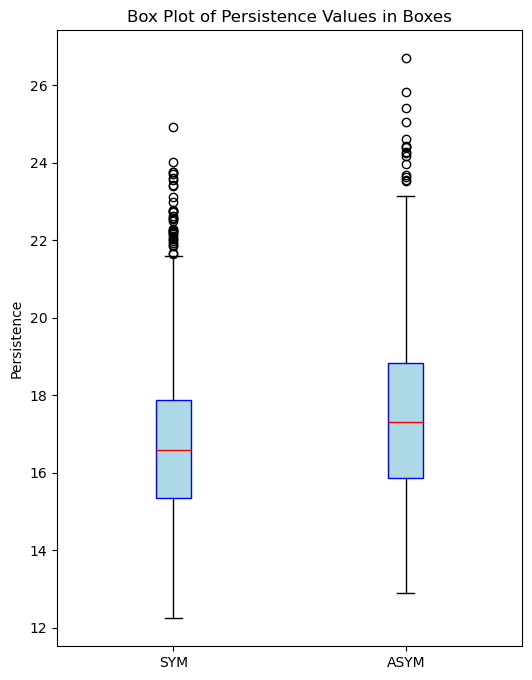

In [4]:
import matplotlib.pyplot as plt


plt.figure(figsize=(6, 8))
plt.boxplot(intensities_list, labels=['SYM', 'ASYM'], patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='blue'),
            medianprops=dict(color='red'),
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'))
plt.title('Box Plot of Persistence Values in Boxes')
plt.ylabel('Intensity')
plt.show()

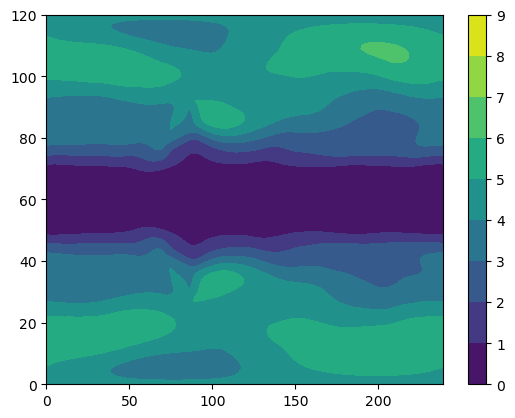

In [17]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

base_path = '/home/links/mf671/DATA/isca_data'
experiment = 'exeter_project_mf_baseline_st_KS'
chunk_size = 30
ds_length = 36000
ds_temp = xr.open_mfdataset(
        f'{base_path}/{experiment}/falwa_vars/atm_daily_uvt_*.nc',
        combine='by_coords',
        parallel=True,
        chunks={'time': chunk_size}  # chunk size of one month (approximate)
        ).isel(time=slice(0, ds_length))
t850 = ds_temp['temp'][:,3,:,:].load()

temp_range = np.arange(0,10,1)
plt.contourf(t850.std(dim='time'),temp_range)
plt.colorbar()

ds_temp.close()

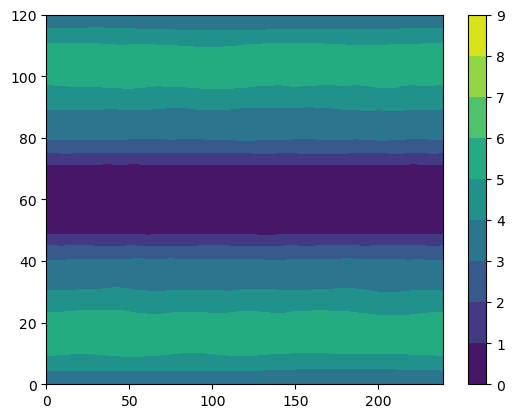

In [18]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

base_path = '/home/links/mf671/DATA/isca_data'
experiment = 'exeter_project_mf_baseline_KS'
chunk_size = 30
ds_length = 36000
ds_temp = xr.open_mfdataset(
        f'{base_path}/{experiment}/falwa_vars/atm_daily_uvt_*.nc',
        combine='by_coords',
        parallel=True,
        chunks={'time': chunk_size}  # chunk size of one month (approximate)
        ).isel(time=slice(0, ds_length))
t850 = ds_temp['temp'][:,3,:,:].load()

temp_range = np.arange(0,10,1)
plt.contourf(t850.std(dim='time'),temp_range)
plt.colorbar()

ds_temp.close()

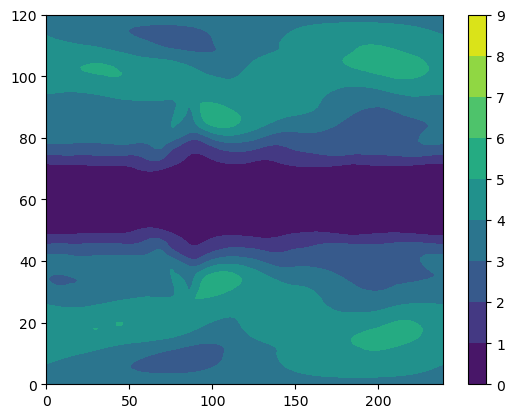

In [19]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

base_path = '/home/links/mf671/DATA/isca_data'
experiment = 'exeter_project_mf_aa_st_KS_30_72,90'
chunk_size = 30
ds_length = 36000
ds_temp = xr.open_mfdataset(
        f'{base_path}/{experiment}/falwa_vars/atm_daily_uvt_*.nc',
        combine='by_coords',
        parallel=True,
        chunks={'time': chunk_size}  # chunk size of one month (approximate)
        ).isel(time=slice(0, ds_length))
t850 = ds_temp['temp'][:,3,:,:].load()

temp_range = np.arange(0,10,1)
plt.contourf(t850.std(dim='time'),temp_range)
plt.colorbar()

ds_temp.close()

In [15]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

base_path = '/home/links/mf671/DATA/isca_data'
experiment = 'exeter_project_mf_aa_st_KS_30_72,90'
ds_egr= xr.open_dataset(
        f'{base_path}/{experiment}/tot/egr850_monthly_2.5x2.5_2-51.nc')
egr_aa = ds_egr['eady_growth_rate'][0,0,:,:]

base_path = '/home/links/mf671/DATA/isca_data'
experiment = 'exeter_project_mf_baseline_st_KS'
ds_egr= xr.open_dataset(
        f'{base_path}/{experiment}/tot/egr850_monthly_2.5x2.5_2-51.nc')
egr_base = ds_egr['eady_growth_rate'][0,0,:,:]

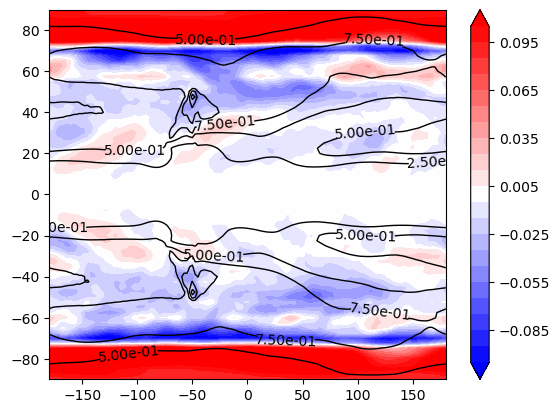

In [28]:
shad = plt.contourf(ds_egr['lon'],ds_egr['lat'],egr_aa-egr_base,np.arange(-5.25e-2,5.3e-2,0.5e-2)*2,cmap='bwr',extend='both')
cont = plt.contour(ds_egr['lon'],ds_egr['lat'],egr_base,colors='k',linewidths=1)
plt.clabel(cont, fmt='%1.2e')
plt.colorbar(shad)